 # Analyse statistique : Les facteurs influençant la performance des marathoniens 

### <u>*INTRODUCTION:*</u>

Le marathon est une épreuve d’endurance exigeante qui demande aux coureurs de maintenir un effort important sur une distance de 42,195 kilomètres. 
La performance réalisée lors d’un marathon peut varier considérablement d’un coureur à l’autre. Ces différences de performance peuvent être liées à de nombreux facteurs, tels que l’âge, le sexe, l’expérience, le niveau d’entraînement, la vitesse moyenne ou encore certaines caractéristiques individuelles des coureurs

L’analyse permettra dans un premier temps de décrire les caractéristiques des coureurs et leur niveau de performance.
Elle cherchera ensuite à mettre en évidence les relations entre les différentes variables disponibles et le temps de course.
Des méthodes statistiques pourront notamment être utilisées afin de déterminer quels facteurs sont les plus fortement associés à la performance et d’évaluer leur importance.

### <u>La question que l’on se pose alors est la suivante :</u>

***Quels sont les facteurs qui influencent la performance d’un coureur lors d’un marathon, mesurée par son temps de course ?***

<br>
Nous avons donc commencé par retravailler notre fichier CSV.

<br>
<br>

***Critique de la qualité des données :***

Dans l’ensemble, le jeu de données est relativement complet. La majorité des variables ne contiennent aucune donnée manquante. Cependant, certaines valeurs sont absentes.

Une autre remarque concerne la variable Event : elle ne contient qu’une seule modalité, « Marathon ». Cette variable n'apporte donc aucune information pour différencier les observations et ne sera pas utile dans l’analyse statistique.

La variable Name comporte également de nombreux noms différents, mais elle n’est pas directement pertinente pour expliquer la performance. Elle pourra principalement servir à identifier les observations.

Enfin, certaines variables devront être transformées avant l’analyse. Par exemple, la variable Time est actuellement enregistrée sous la forme « heures:minutes ». Pour réaliser des calculs statistiques, il sera préférable de la convertir en une durée numérique, par exemple en secondes ou en minutes. De même, les variables Date et Date of Birth devront être converties dans un format de date afin de pouvoir calculer notamment l’âge des coureurs au moment de la course.

***Ajout de deux variables quantitatives + Nettoyage des données***

1) l’âge du marathonien au moment de sa participation au marathon  
2) Sa vitesse moyenne sur le marathon.

Ces deux nouvelles variables vont nous permettre d’être plus précis dans la réalisation de nos statistiques descriptives, en apportant davantage d’informations sur les caractéristiques des participants et leurs performances.

Le nombre d'observations avant et après le nettoyage a été comparé afin de quantifier les suppressions effectuées. Les autres valeurs manquantes ont été traitées en fonction des variables utilisées dans chaque analyse, afin de conserver autant d'informations pertinentes que possible.

Avant :   17002     observations                                      |  Après :   16819        observations     | Total Supprimées : 183   

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

dataFrame = pd.read_csv("data_Set/dataSetMarathon.csv",delimiter=";", usecols=range(10))

lignes_avant = len(dataFrame)
print("Nombre de lignes avant nettoyage :", lignes_avant)

dataFrame.columns = dataFrame.columns.str.strip()

dataFrame = dataFrame.dropna(subset=["Date of Birth"])

dataFrame["Date of Birth"] = pd.to_datetime(dataFrame["Date of Birth"], dayfirst=True)

dataFrame["Date"] = pd.to_datetime(dataFrame["Date"], dayfirst=True)

dataFrame["Time"] = pd.to_timedelta(dataFrame["Time"])

dataFrame["Age"] = (dataFrame["Date"].dt.year - dataFrame["Date of Birth"].dt.year - ((dataFrame["Date"].dt.month < dataFrame["Date of Birth"].dt.month) | ((dataFrame["Date"].dt.month == dataFrame["Date of Birth"].dt.month) &(dataFrame["Date"].dt.day < dataFrame["Date of Birth"].dt.day))))

distance_marathon = 42.195

dataFrame["Speed"] = distance_marathon / (dataFrame["Time"].dt.total_seconds() / 3600)

dataFrame["Time"] = dataFrame["Time"].astype(str).str.replace("0 days ", "")


# Nombre de lignes après suppression
lignes_apres = len(dataFrame)
print("Nombre de lignes après suppression :", lignes_apres)

# Nombre de lignes supprimées
print("Nombre de lignes supprimées :", lignes_avant - lignes_apres)


dataFrame.head(20)


Nombre de lignes avant nettoyage : 17002
Nombre de lignes après suppression : 16819
Nombre de lignes supprimées : 183


,Rank,Time,Name,Country,Date of Birth,Place,City,Date,Gender,Event,Age,Speed
0,9836,02:11:40,Øyvind Dahl,NOR,1951-05-12,2,Karl Marx Stadt,1980-05-03,Men,Marathon,28,19.228101
1,4898,02:29:05,Élissa Legault,CAN,1994-06-20,23,Valencia,2025-12-07,Women,Marathon,31,16.981778
2,5038,02:29:13,Élissa Legault,CAN,1994-06-20,8,Ottawa,2026-05-24,Women,Marathon,31,16.966603
3,4625,02:28:51,Ágnes Sipka,HUN,1954-08-14,1,Budapest,1986-10-26,Women,Marathon,32,17.008398
4,1799,02:25:15,Živilé Balčiunaitė,LTU,1979-04-03,2,Tokyo,2005-11-20,Women,Marathon,26,17.429948
5,3326,02:27:28,Živilé Balčiunaitė,LTU,1979-04-03,5,Tokyo,2004-11-21,Women,Marathon,25,17.167948
6,3951,02:28:10,Živilé Balčiunaitė,LTU,1979-04-03,2,Los Angeles,2005-03-06,Women,Marathon,25,17.086839
7,5408,02:29:33,Živilé Balčiunaitė,LTU,1979-04-03,11,National Stadium,2008-08-17,Women,Marathon,29,16.928786
8,2193,02:07:59,Aadam Ismaeel Khamis,BRN,1989-02-12,1,Valencia,2011-11-27,Men,Marathon,22,19.781482
9,3886,02:09:09,Aadam Ismaeel Khamis,BRN,1989-02-12,3,Köln,2009-10-04,Men,Marathon,20,19.602787


Le code Python ci-dessous permet de représenter sous forme de diagramme circulaire (camembert) la répartition des observations avant et après le nettoyage des données. Il montre que 16 819 observations (98,92 %) ont été conservées, tandis que 183 observations (1,08 %) ont été supprimées, car leur date de naissance était manquante. Ce graphique permet donc de visualiser rapidement la faible proportion de données supprimées et de constater que la grande majorité du jeu de données a été conservée pour la suite de l’analyse statistique

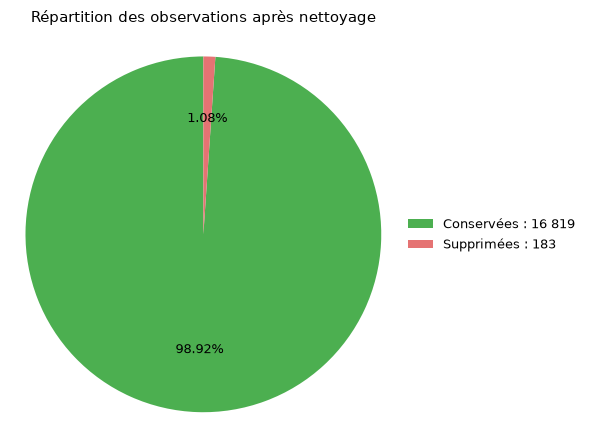

In [9]:

import matplotlib.pyplot as plt

observations_avant = 17002
observations_apres = 16819
observations_supprimees = observations_avant - observations_apres

valeurs = [observations_apres, observations_supprimees]
labels = ["Observations conservées", "Observations supprimées"]
couleurs = ["#4CAF50", "#E57373"]

fig, ax = plt.subplots(figsize=(6, 4.5))

parts, textes, pourcentages = ax.pie(
    valeurs,
    labels=None,
    colors=couleurs,
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.65,
    textprops={"fontsize": 9}
)

ax.legend(
    parts,
    [
        f"Conservées : {observations_apres:,}".replace(",", " "),
        f"Supprimées : {observations_supprimees:,}".replace(",", " ")
    ],
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=9,
    frameon=False
)

ax.set_title(
    "Répartition des observations après nettoyage",
    fontsize=11,
    pad=12,
    loc="center"
)

ax.axis("equal")
plt.tight_layout()
plt.show()



### Analyse descriptive


VOIR CE QUON FAIT DU COUP

Dans un premier temps, une analyse descriptive sera réalisée afin de mieux comprendre la structure et les principales caractéristiques du jeu de données.

Nous étudierons notamment la distribution des temps de course, qui constitue la variable principale de notre étude. Des indicateurs statistiques tels que la moyenne, la médiane, le minimum, le maximum et l’écart-type permettront de caractériser les performances des participants.

Des représentations graphiques pourront également être utilisées, notamment :

un histogramme des temps de course afin d’observer leur distribution ;

une boîte à moustaches (boxplot) afin d’identifier la dispersion et les éventuelles valeurs extrêmes ;

un graphique comparant le temps de course selon le sexe ;

un graphique permettant d’étudier la relation entre l’âge et le temps de course ;

éventuellement une comparaison des performances selon le pays ou la ville de la course, si ces variables sont pertinentes.

Cette analyse descriptive permettra ainsi d’identifier les principales caractéristiques des coureurs et de leurs performances avant de réaliser des analyses statistiques plus approfondies visant à déterminer les facteurs associés au temps de course.

ce qu'il y a potentiellement a faire :

. Distribution du temps de course
Variable : time
- Faire un histogramme pour voir la répartition des temps.
- Calculer la moyenne, la médiane, l'écart-type et les quartiles.
- Repérer les temps particulièrement faibles ou élevés.

2. Distribution du temps selon le genre

Variables : time, gender
- Comparer les distributions avec des histogrammes ou des boxplots.
- Comparer les moyennes et les médianes.
- Observer la dispersion des temps entre les deux groupes.
Objectif : étudier les différences de performance entre les genres.

3. Analyse de l'âge et des performances

Variables : age, time, speed
- Faire un nuage de points âge-vitesse.
- Étudier la corrélation entre l'âge et le temps.
- Comparer les résultats par tranche d'âge.
Objectif : déterminer si l'âge est associé à une variation des performances.


Analyse des performances selon le pays

Variables : country, time, gender
- Comparer les temps médians des pays suffisamment représentés.
- Examiner les différences entre les genres au sein de chaque pays.
- Vérifier les effectifs avant de comparer les groupes.
Objectif : mettre en évidence les différences observées entre pays, sans les attribuer automatiquement à la nationalité.

Modélisation : régression linéaire simple
Oui, c'est possible et pertinent.

Je choisirais :
- Variable explicative \(X\) : age
- Variable expliquée \(Y\) : time, converti en heures ou en secondes.
Le modèle cherchera à déterminer s'il existe une relation linéaire entre l'âge et le temps de course.

Validation du modèle : analyse des résidus
C'est également possible.

Après avoir construit la régression age → time, j'analyserais :
- Résidus en fonction des valeurs prédites : vérifier si les erreurs sont réparties aléatoirement autour de zéro.
- Distribution des résidus : vérifier si elle est approximativement normale.
- Valeurs atypiques : identifier les coureurs dont les temps sont mal prédits par le modèle.
L'objectif est de déterminer si une droite décrit correctement la relation entre l'âge et le temps, ou si un modèle linéaire est insuffisant.

Test bilatéral : méthode de Welch
Oui, tu peux réaliser un test de Welch. C'est même un bon choix pour comparer deux groupes dont les variances ou les effectifs peuvent différer.

Je testerais :
- Variable étudiée : time
- Groupe 1 : hommes
- Groupe 2 : femmes
- Hypothèse nulle \(H_0\) : les moyennes des temps de course sont égales.
- Hypothèse alternative \(H_1\) : les moyennes des temps de course sont différentes.
Le test bilatéral permet de vérifier s'il existe une différence statistiquement significative, sans supposer à l'avance quel groupe a le temps moyen le plus faible.

Il faudra contrôler les données manquantes et les valeurs aberrantes. Pour une comparaison rigoureuse, il faut aussi tenir compte du fait que les temps peuvent varier selon l'âge et le marathon considéré.


Analyse multivariée : déterminants des performances
C'est possible, et c'est une bonne façon de terminer ton travail.

Je prendrais les variables suivantes :
Variable	Rôle
time	Variable à expliquer
age	Facteur explicatif
gender	Facteur explicatif catégoriel
country	Facteur explicatif catégoriel
date	Facteur temporel, si plusieurs années sont présentes
city	Facteur lié au lieu, si plusieurs marathons sont présents
L'objectif serait de construire une régression multiple pour examiner l'association de chaque facteur avec le temps de course, en tenant compte des autres variables du modèle.

Je ne mettrais pas rank et speed automatiquement dans ce modèle : le rang dépend du classement, et la vitesse est étroitement liée au temps. Les utiliser comme variables explicatives pourrait rendre l'analyse redondante ou trompeuse.

